In [5]:
import json
import os
import glob
import unicodedata

from PIL import Image, ImageDraw
import numpy as np
import cv2
from sklearn.preprocessing import LabelEncoder
from matplotlib import pyplot as plt


def normalize_label(label):
    """
    JSON'lardaki label isimlerini standart İngilizce büyük harflere çevirir.

    Örnek:
    VİTREUS          -> VITREUS
    vitreus          -> VITREUS
    CHORİOCAPİLLARİS -> CHORIOCAPILLARIS
    İZ               -> IZ
    """
    if label is None:
        return None

    label = str(label).strip()

    # Türkçe I karakterlerini İngilizce karşılıklarına dönüştür
    label = label.replace('İ', 'I')
    label = label.replace('ı', 'i')

    # Diğer Unicode işaretlerini ayır
    label = unicodedata.normalize('NFKD', label)

    # Birleşik karakter işaretlerini kaldır
    label = ''.join(
        character
        for character in label
        if not unicodedata.combining(character)
    )

    return label.upper()


# Yalnızca output_normal_*.png kayıtlarını içeren JSON dosyaları
json_files = [
    'jsons/labels_my-project-name_2026-06-07-09-06-32.json',
    'jsons/labels_my-project-name_2026-06-08-06-55-55.json',
    'jsons/labels_my-project-name_2026-06-08-10-27-57.json',
    'jsons/labels_my-project-name_2026-06-09-06-58-52.json',
    'jsons/labels_my-project-name_2026-06-09-09-46-04.json',
    'jsons/labels_my-project-name_2026-06-21-11-21-04.json',
    'jsons/labels_my-project-name_corrected_filenames.json'
]


# Bütün output_normal kayıtlarını burada birleştir
all_labels = {}

for jf in json_files:

    if not os.path.exists(jf):
        print(f"⚠️ JSON dosyası bulunamadı: {jf}")
        continue

    with open(jf, 'r', encoding='utf-8') as file:
        data = json.load(file)

    if not isinstance(data, dict):
        print(f"⚠️ JSON ana yapısı dict değil, atlandı: {jf}")
        continue

    for name, entry in data.items():

        # Yalnızca output_normal_ ile başlayan görüntüleri al
        image_name = os.path.basename(str(name))

        if not image_name.lower().startswith('output_normal_'):
            continue

        # Sadece görüntü entry'si olan dict kayıtlarını işle
        if not isinstance(entry, dict):
            print(
                f"⚠️ Entry dict değil, atlandı: "
                f"dosya={jf}, görüntü={image_name}"
            )
            continue

        regions = entry.get('regions', {})

        if isinstance(regions, dict):
            region_iterator = regions.values()

        elif isinstance(regions, list):
            region_iterator = regions

        else:
            print(
                f"⚠️ Geçersiz regions yapısı: "
                f"dosya={jf}, görüntü={image_name}"
            )
            continue

        # Label isimlerini normalize et
        for region in region_iterator:

            if not isinstance(region, dict):
                continue

            region_attributes = region.setdefault(
                'region_attributes',
                {}
            )

            if not isinstance(region_attributes, dict):
                region_attributes = {}
                region['region_attributes'] = region_attributes

            raw_label = region_attributes.get('label')

            if raw_label is not None:
                region_attributes['label'] = normalize_label(raw_label)

        # Aynı görüntü daha önce eklenmediyse doğrudan ekle
        if image_name not in all_labels:
            all_labels[image_name] = entry

        else:
            # Aynı görüntü birden fazla JSON'da varsa region'ları birleştir
            existing_regions = all_labels[image_name].get('regions', {})

            if isinstance(existing_regions, dict):

                if isinstance(regions, dict):
                    new_regions = regions.values()
                else:
                    new_regions = regions

                # Region ID çakışmalarını önlemek için yeni ID oluştur
                for region in new_regions:
                    new_region_id = str(len(existing_regions))
                    existing_regions[new_region_id] = region

            elif isinstance(existing_regions, list):

                if isinstance(regions, dict):
                    existing_regions.extend(regions.values())
                else:
                    existing_regions.extend(regions)

            else:
                print(
                    f"⚠️ Aynı görüntünün regions yapısı birleştirilemedi: "
                    f"{image_name}"
                )


print(f"✅ Toplam output_normal görüntü etiketi sayısı: {len(all_labels)}")

print("\nYüklenen görüntü kayıtları:")
for image_name in sorted(all_labels.keys()):
    print(f" - {image_name}")

✅ Toplam output_normal görüntü etiketi sayısı: 50

Yüklenen görüntü kayıtları:
 - output_normal_1.png
 - output_normal_11.png
 - output_normal_12.png
 - output_normal_13.png
 - output_normal_14.png
 - output_normal_15.png
 - output_normal_16.png
 - output_normal_17.png
 - output_normal_18.png
 - output_normal_19.png
 - output_normal_2.png
 - output_normal_20.png
 - output_normal_21.png
 - output_normal_22.png
 - output_normal_23.png
 - output_normal_24.png
 - output_normal_25.png
 - output_normal_26.png
 - output_normal_27.png
 - output_normal_28.png
 - output_normal_29.png
 - output_normal_3.png
 - output_normal_30.png
 - output_normal_31.png
 - output_normal_32.png
 - output_normal_33.png
 - output_normal_34.png
 - output_normal_35.png
 - output_normal_36.png
 - output_normal_38.png
 - output_normal_39.png
 - output_normal_4.png
 - output_normal_40.png
 - output_normal_41.png
 - output_normal_42.png
 - output_normal_43.png
 - output_normal_44.png
 - output_normal_45.png
 - output_nor

In [6]:
for jf in json_files:
    if not os.path.exists(jf):
        continue

    with open(jf, 'r', encoding='utf-8') as file:
        test_data = json.load(file)

    print(f"\nDosya: {jf}")
    print("Ana tip:", type(test_data).__name__)

    if isinstance(test_data, dict):
        for key, value in list(test_data.items())[:3]:
            print(
                "Key:",
                repr(key),
                "| Value tipi:",
                type(value).__name__
            )


Dosya: jsons/labels_my-project-name_2026-06-07-09-06-32.json
Ana tip: dict
Key: 'output_normal_1.png' | Value tipi: dict
Key: 'output_normal_2.png' | Value tipi: dict
Key: 'output_normal_3.png' | Value tipi: dict

Dosya: jsons/labels_my-project-name_2026-06-08-06-55-55.json
Ana tip: dict
Key: 'output_normal_24.png' | Value tipi: dict
Key: 'output_normal_25.png' | Value tipi: dict
Key: 'output_normal_26.png' | Value tipi: dict

Dosya: jsons/labels_my-project-name_2026-06-08-10-27-57.json
Ana tip: dict
Key: 'output_normal_40.png' | Value tipi: dict
Key: 'output_normal_41.png' | Value tipi: dict

Dosya: jsons/labels_my-project-name_2026-06-09-06-58-52.json
Ana tip: dict
Key: 'output_normal_40.png' | Value tipi: dict
Key: 'output_normal_41.png' | Value tipi: dict
Key: 'output_normal_42.png' | Value tipi: dict

Dosya: jsons/labels_my-project-name_2026-06-09-09-46-04.json
Ana tip: dict
Key: 'output_normal_40.png' | Value tipi: dict
Key: 'output_normal_41.png' | Value tipi: dict
Key: 'output

In [7]:
# Arka plan: 0
# Retinal katmanlar ve bölgeler: 1-12

class_dict = {
    'VITREUS':           1,
    'RNFL':              2,
    'GCL':               3,
    'IPL':               4,
    'INL':               5,
    'OPL':               6,
    'ONL':               7,
    'ELM':               8,
    'EZ':                9,
    'IZ':               10,
    'RPE':              11,
    'CHORIOCAPILLARIS': 12
}

# Toplam sınıf sayısı:
# 1 arka plan + 12 anotasyon sınıfı = 13
NUM_CLASSES = max(class_dict.values()) + 1

print(f"Arka plan dahil toplam sınıf sayısı: {NUM_CLASSES}")
print(f"Anotasyon sınıfı sayısı: {len(class_dict)}")


# Görüntü ve maske klasörleri
original_images = 'cropped_output/'
result_save = 'maskedoutputs/'

os.makedirs(result_save, exist_ok=True)

Arka plan dahil toplam sınıf sayısı: 13
Anotasyon sınıfı sayısı: 12


In [8]:
def get_data(data):
    """
    Tek bir annotation entry'si için X, Y ve L listelerini döner.
    """
    X, Y, L = [], [], []
    for region in data['regions'].values():
        X.append(region['shape_attributes']['all_points_x'])
        Y.append(region['shape_attributes']['all_points_y'])
        L.append(region['region_attributes']['label'])
    return Y, X, L

def get_mask(X, Y, nx, ny, labels, class_dict):
    """
    Çokgenleri doldurarak (nx x ny) boyutunda bir mask üretir.
    Label değerlerini class_dict'e göre atar.
    """
    mask = np.zeros((nx, ny), dtype=np.uint8)
    for xs, ys, lbl in zip(X, Y, labels):
        # polygon için (x,y) çiftleri listesi
        polygon = list(zip(xs, ys))
        # img: width=ny, height=nx → arr shape = (nx, ny)
        img = Image.new("L", (ny, nx), 0)
        ImageDraw.Draw(img).polygon(polygon, fill=1, outline=1)
        arr = np.array(img)  # artık (nx, ny) boyutunda

        mask[arr == 1] = class_dict[lbl]

    return mask



In [9]:
for name, annotation in all_labels.items():
    # aligned_layer_*.png → aligned_normal_*.png çevir
    image_name = name
    img_path = os.path.join(original_images, image_name)
    if not os.path.isfile(img_path):
        continue

    image = Image.open(img_path)
    nx, ny = image.size[1], image.size[0]  # (height, width)

    Y, X, L = get_data(annotation)
    mask = get_mask(X, Y, nx, ny, L, class_dict)

    # Grayscale mask kaydı
    mask_img = Image.fromarray(mask, mode='L')
    out_name = image_name.rsplit('.', 1)[0] + '.png'
    mask_img.save(os.path.join(result_save, out_name), format='PNG')

print("✅ Mask üretimi tamamlandı.")


✅ Mask üretimi tamamlandı.


In [10]:
# Mask dosyalarını sırayla al
mask_paths = sorted(glob.glob(os.path.join(result_save, "*.png")))

train_masks = []
for mp in mask_paths:
    m = cv2.imread(mp, cv2.IMREAD_GRAYSCALE)
    # Yeniden boyutlandırma: (width, height) = (504, 496)
    m = cv2.resize(m, (504, 496), interpolation=cv2.INTER_NEAREST)
    train_masks.append(m)
train_masks = np.array(train_masks)

# LabelEncoder ile (isteğe bağlı) encode et
n, h, w = train_masks.shape  # h=496, w=504
train_masks_reshaped = train_masks.reshape(-1, 1)
le = LabelEncoder()
encoded = le.fit_transform(train_masks_reshaped)
train_masks_input = encoded.reshape(n, h, w, 1)

print(f"✅ train_masks_input boyutları: {train_masks_input.shape}")


/Users/emirdogan/anaconda3/envs/brain-tumor-tf/lib/python3.11/site-packages/sklearn/preprocessing/_label.py:120: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


✅ train_masks_input boyutları: (50, 496, 504, 1)


Mask 0 etiketi: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Mask 1 etiketi: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Mask 2 etiketi: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Mask 3 etiketi: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Mask 4 etiketi: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


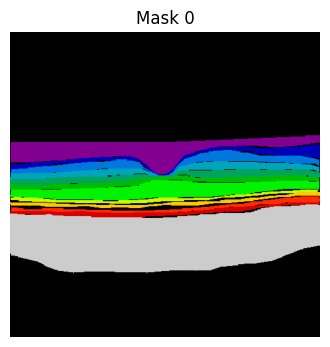

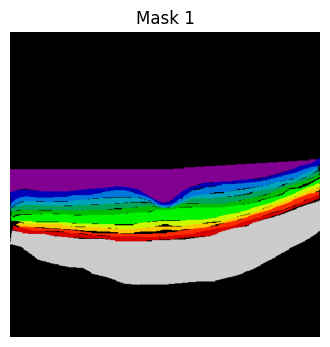

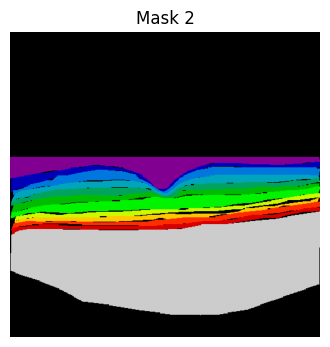

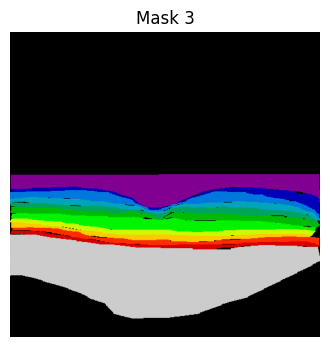

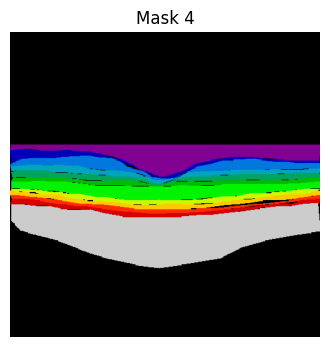

In [11]:
for i in range(min(5, train_masks_input.shape[0])):
    print(f"Mask {i} etiketi:", np.unique(train_masks_input[i]))
    plt.figure(figsize=(4,4))
    plt.imshow(train_masks_input[i, ..., 0], cmap='nipy_spectral')
    plt.title(f"Mask {i}")
    plt.axis('off')
plt.show()
